# Treino de Instance Segmentation - milho (corn) - YOLO no Colab

Esse notebook parte do dataset exportado do Roboflow em formato **COCO Segmentation**
(preserva os poligonos de instancia, diferente dos formatos "YOLOv8/YOLO11/YOLO26"
listados no Roboflow pra esse projeto, que convertem pra bounding box e perdem a mascara).

Passo 1: sobe o `blick-corn-analyzer.zip` pro seu Google Drive, numa pasta tipo
`MyDrive/milho/blick-corn-analyzer.zip`.

Antes de treinar: **Ambiente de execucao > Alterar tipo de ambiente de execucao > GPU (T4)**.

In [1]:
!pip install -q ultralytics pycocotools
import ultralytics
ultralytics.checks()

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.4/235.7 GB disk)


## Monta o Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Descompacta o dataset COCO

Ajusta `ZIP_PATH` se o nome/local do zip no seu Drive for diferente.

In [3]:
ZIP_PATH = "/content/drive/MyDrive/milho/blick-corn-analyzer.zip"
RAW_DIR = "/content/coco_raw"

import osc
os.makedirs(RAW_DIR, exist_ok=True)
!unzip -q "{ZIP_PATH}" -d {RAW_DIR}
print("Extraido em:", RAW_DIR)

Extraido em: /content/coco_raw


## Confere a estrutura extraida

Precisa aparecer uma pasta por split (train/valid/test), cada uma com imagens
e um arquivo `.json` de anotacao (normalmente `_annotations.coco.json`).

In [4]:
import os

for raiz, pastas, arquivos in os.walk(RAW_DIR):
    nivel = raiz.replace(RAW_DIR, "").count(os.sep)
    if nivel <= 1:
        jsons = [a for a in arquivos if a.endswith(".json")]
        print(raiz, "->", f"{len(arquivos)} arquivos", f"| json: {jsons}" if jsons else "")

/content/coco_raw -> 1 arquivos 
/content/coco_raw/train -> 4989 arquivos | json: ['_annotations.coco.json']
/content/coco_raw/valid -> 1223 arquivos | json: ['_annotations.coco.json']
/content/coco_raw/test -> 674 arquivos | json: ['_annotations.coco.json']


## Localiza automaticamente os jsons de cada split

Procura por qualquer `.json` dentro de pastas cujo nome contenha "train", "valid"/"val"
ou "test". Se a estrutura do seu zip for diferente disso, essa celula avisa em vez de
quebrar silenciosamente.

In [5]:
import glob

def encontra_json(padrao):
    candidatos = []
    for j in glob.glob(f"{RAW_DIR}/**/*.json", recursive=True):
        pasta = os.path.basename(os.path.dirname(j)).lower()
        if padrao in pasta:
            candidatos.append(j)
    return candidatos

splits_json = {}
for nome, padrao in [("train", "train"), ("valid", "val"), ("test", "test")]:
    encontrados = encontra_json(padrao)
    if len(encontrados) == 1:
        splits_json[nome] = encontrados[0]
        print(f"{nome}: {encontrados[0]}")
    else:
        print(f"ATENCAO: encontrei {len(encontrados)} candidatos pra '{nome}': {encontrados}")
        print("Ajusta o dicionario splits_json manualmente na proxima celula se precisar.")

assert len(splits_json) == 3, "Nao encontrei os 3 splits automaticamente - ajusta splits_json manualmente antes de continuar."

train: /content/coco_raw/train/_annotations.coco.json
valid: /content/coco_raw/valid/_annotations.coco.json
test: /content/coco_raw/test/_annotations.coco.json


## Inspeciona o conteudo do COCO json (sanity check antes de converter)

So pra conferir quantas imagens/anotacoes/categorias tem, antes de gerar os labels.

In [6]:
import json as json_lib

for nome, caminho in splits_json.items():
    with open(caminho) as f:
        d = json_lib.load(f)
    print(f"--- {nome} ---")
    print("imagens:", len(d["images"]))
    print("anotacoes:", len(d["annotations"]))
    print("categorias:", d["categories"])
    print()

--- train ---
imagens: 4988
anotacoes: 30883
categorias: [{'id': 0, 'name': 'Blick-corn-analyze', 'supercategory': 'none'}, {'id': 1, 'name': 'corn', 'supercategory': 'Blick-corn-analyze'}]

--- valid ---
imagens: 1222
anotacoes: 6050
categorias: [{'id': 0, 'name': 'Blick-corn-analyze', 'supercategory': 'none'}, {'id': 1, 'name': 'corn', 'supercategory': 'Blick-corn-analyze'}]

--- test ---
imagens: 673
anotacoes: 3795
categorias: [{'id': 0, 'name': 'Blick-corn-analyze', 'supercategory': 'none'}, {'id': 1, 'name': 'corn', 'supercategory': 'Blick-corn-analyze'}]



## Converte COCO -> formato YOLO-seg

Conversor proprio (nao depende de funcao interna do Ultralytics que pode mudar de versao
pra versao). Para cada imagem: gera um `.txt` com uma linha por instancia anotada
(`classe x1 y1 x2 y2 ...` normalizado 0-1). Imagens sem nenhuma anotacao (as "null" do
Roboflow) ficam sem `.txt` - o Ultralytics trata isso como imagem de fundo, sem objeto.

O campo `segmentation` do COCO pode vir em dois formatos: **poligono** (lista de pontos)
ou **RLE** (mascara binaria comprimida). O Roboflow pode exportar qualquer um dos dois
dependendo da anotacao, entao o conversor abaixo trata ambos - quando e RLE, decodifica a
mascara e extrai o contorno com OpenCV.

In [7]:
import shutil
import numpy as np
import cv2
from pathlib import Path
from pycocotools import mask as mask_utils

DATASET_DIR = Path("/content/dataset")

def segmentacao_para_poligonos(seg, img_w, img_h):
    """Retorna lista de arrays Nx2 (um array por poligono/instancia), em pixels."""
    poligonos = []
    if isinstance(seg, dict):
        # formato RLE
        try:
            if isinstance(seg.get("counts"), list):
                rle = mask_utils.frPyObjects(seg, img_h, img_w)
            else:
                rle = seg
            mascara = mask_utils.decode(rle)
            if mascara.ndim == 3:
                mascara = mascara[:, :, 0]
            contornos, _ = cv2.findContours(mascara.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for c in contornos:
                if len(c) >= 3:
                    poligonos.append(c.reshape(-1, 2).astype(float))
        except Exception as e:
            print(f"Aviso: falha ao decodificar RLE ({e}), anotacao ignorada")
    elif isinstance(seg, list):
        for parte in seg:
            if isinstance(parte, list) and len(parte) >= 6:
                poligonos.append(np.array(parte, dtype=float).reshape(-1, 2))
    return poligonos


def coco_to_yolo_seg(json_path, imagens_dir, out_images_dir, out_labels_dir, categoria_para_idx):
    with open(json_path) as f:
        d = json_lib.load(f)

    out_images_dir.mkdir(parents=True, exist_ok=True)
    out_labels_dir.mkdir(parents=True, exist_ok=True)

    imagens_por_id = {img["id"]: img for img in d["images"]}
    anotacoes_por_imagem = {}
    for ann in d["annotations"]:
        anotacoes_por_imagem.setdefault(ann["image_id"], []).append(ann)

    n_copiadas, n_sem_imagem, n_anotacoes_ignoradas = 0, 0, 0
    for img_id, img in imagens_por_id.items():
        origem = imagens_dir / img["file_name"]
        if not origem.exists():
            n_sem_imagem += 1
            continue

        destino = out_images_dir / img["file_name"]
        shutil.copy(origem, destino)
        n_copiadas += 1

        anns = anotacoes_por_imagem.get(img_id, [])
        if not anns:
            continue  # imagem "null": sem objeto, sem .txt

        linhas = []
        w, h = img["width"], img["height"]
        for ann in anns:
            classe_idx = categoria_para_idx[ann["category_id"]]
            seg = ann.get("segmentation")
            if not seg:
                continue
            poligonos = segmentacao_para_poligonos(seg, w, h)
            if not poligonos:
                n_anotacoes_ignoradas += 1
                continue
            for pts in poligonos:
                coords_norm = []
                for x, y in pts:
                    coords_norm.append(f"{x / w:.6f}")
                    coords_norm.append(f"{y / h:.6f}")
                linhas.append(str(classe_idx) + " " + " ".join(coords_norm))

        if linhas:
            txt_path = out_labels_dir / (Path(img["file_name"]).stem + ".txt")
            txt_path.write_text("\n".join(linhas))

    print(f"{json_path}: {n_copiadas} imagens copiadas, {n_sem_imagem} sem imagem no zip, {n_anotacoes_ignoradas} anotacoes nao decodificadas")


# categorias: pega do primeiro split, assume mesmas categorias nos 3
with open(splits_json["train"]) as f:
    categorias = json_lib.load(f)["categories"]
categorias_ordenadas = sorted(categorias, key=lambda c: c["id"])
categoria_para_idx = {c["id"]: i for i, c in enumerate(categorias_ordenadas)}
nomes_classes = [c["name"] for c in categorias_ordenadas]
print("Classes:", nomes_classes)

for nome, json_path in splits_json.items():
    imagens_dir = Path(json_path).parent
    coco_to_yolo_seg(
        json_path=json_path,
        imagens_dir=imagens_dir,
        out_images_dir=DATASET_DIR / "images" / nome,
        out_labels_dir=DATASET_DIR / "labels" / nome,
        categoria_para_idx=categoria_para_idx,
    )

Classes: ['Blick-corn-analyze', 'corn']
/content/coco_raw/train/_annotations.coco.json: 4988 imagens copiadas, 0 sem imagem no zip, 0 anotacoes nao decodificadas
/content/coco_raw/valid/_annotations.coco.json: 1222 imagens copiadas, 0 sem imagem no zip, 0 anotacoes nao decodificadas
/content/coco_raw/test/_annotations.coco.json: 673 imagens copiadas, 0 sem imagem no zip, 0 anotacoes nao decodificadas


## Confere o resultado da conversao

In [8]:
for nome in ["train", "valid", "test"]:
    n_img = len(list((DATASET_DIR / "images" / nome).glob("*")))
    n_lbl = len(list((DATASET_DIR / "labels" / nome).glob("*.txt")))
    print(f"{nome}: {n_img} imagens, {n_lbl} labels (.txt) -- diferenca = imagens sem objeto anotado (null)")

train: 4988 imagens, 4492 labels (.txt) -- diferenca = imagens sem objeto anotado (null)
valid: 1222 imagens, 1089 labels (.txt) -- diferenca = imagens sem objeto anotado (null)
test: 673 imagens, 610 labels (.txt) -- diferenca = imagens sem objeto anotado (null)


## Gera o data.yaml

In [9]:
data_yaml = f"""path: {DATASET_DIR}
train: images/train
val: images/valid
test: images/test

names:
"""
for i, nome_classe in enumerate(nomes_classes):
    data_yaml += f"  {i}: {nome_classe}\n"

DATA_YAML_PATH = DATASET_DIR / "data.yaml"
DATA_YAML_PATH.write_text(data_yaml)
print(data_yaml)

path: /content/dataset
train: images/train
val: images/valid
test: images/test

names:
  0: Blick-corn-analyze
  1: corn



In [10]:
import os
RUN_DIR = "runs/segment/milho_corn_seg"
BACKUP_ZIP = "/content/drive/MyDrive/milho/relatorio_treino_segmentacao_completo.zip"
os.makedirs(RUN_DIR, exist_ok=True)
!unzip -q "{BACKUP_ZIP}" -d {RUN_DIR}
!ls {RUN_DIR}/weights

best.pt  last.pt


## Treino

Segmentacao e mais pesada que classificacao (calcula mascara por instancia, nao so uma
classe por imagem) - espera um treino mais demorado. `batch=16` e um ponto de partida
seguro pra T4 do Colab gratuito; baixa pra 8 se der "out of memory".

Essa celula so treina se ainda nao existir um `best.pt` salvo em `RUN_DIR` - assim, se a
sessao cair e voce rodar essa celula de novo depois de recuperar o backup do Drive, ela
nao retreina do zero sem querer.

In [11]:
import os
from ultralytics import YOLO

MODEL = "yolo26n-seg.pt"   # se der erro ao baixar, troca por "yolo11n-seg.pt"
EPOCHS = 100
IMGSZ = 640
BATCH = 16
NAME = "milho_corn_seg"

RUN_DIR = f"runs/segment/{NAME}"
BEST_PT = f"{RUN_DIR}/weights/best.pt"

if os.path.exists(BEST_PT):
    print(f"Pesos ja existem em {BEST_PT}, carregando SEM retreinar.")
    model = YOLO(BEST_PT)
else:
    print("Pesos nao encontrados, treinando do zero...")
    model = YOLO(MODEL)
    results = model.train(
        data=str(DATA_YAML_PATH),
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        patience=20,
        name=NAME,
        device=0,
    )

print("\nRUN_DIR:", RUN_DIR)

Pesos ja existem em runs/segment/milho_corn_seg/weights/best.pt, carregando SEM retreinar.

RUN_DIR: runs/segment/milho_corn_seg


In [12]:
metrics_limpo = model.val(data=str(DATA_YAML_PATH), split="test", conf=0.4)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 136 layers, 2,689,274 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3240.1±1651.0 MB/s, size: 631.4 KB)
val: Scanning /content/dataset/labels/test... 610 images, 63 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 673/673 801.4it/s 0.8s
val: /content/dataset/images/test/20260704145559-f04dfb70_jpg.rf.bR6AWJDMfUTBaFujNSJ0.jpg: corrupt JPEG restored and saved
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 1.8it/s 24.6s
                   all        673       3795      0.891      0.702      0.695      0.532      0.854      0.672      0.658      0.388
                  corn        610       3795      0.891      0.702      0.695      0.532      0.854      0.672      0.658      0.3

In [13]:
from google.colab import files
files.download("/content/runs/segment/val/confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Salva o treino completo no Drive AGORA

Roda essa celula assim que o treino terminar, antes de qualquer outra coisa - e a licao
do treino de classificacao, onde perder a sessao sem ter feito esse backup custou ter
que refazer avaliacao depois.

In [ ]:
import shutil as shutil_lib

BACKUP_NAME = "relatorio_treino_segmentacao_completo"
destino_zip = shutil_lib.make_archive(f"/content/drive/MyDrive/milho/{BACKUP_NAME}", 'zip', RUN_DIR)
print("Backup salvo em:", destino_zip)

Backup salvo em: /content/drive/MyDrive/milho/relatorio_treino_segmentacao_completo.zip


## Loss de treino vs. validacao por epoca (overfitting)

Essa e a parte que nao existia no treino feito direto no Roboflow. Aqui, por termos
rodado o treino nos mesmos moldes do modelo de classificacao, o `results.csv` registra
loss de treino e de validacao separados por epoca.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(f"{RUN_DIR}/results.csv")
df.columns = [c.strip() for c in df.columns]
print(df.columns.tolist())

['epoch', 'time', 'train/box_loss', 'train/seg_loss', 'train/cls_loss', 'train/l1_loss', 'train/sem_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'metrics/precision(M)', 'metrics/recall(M)', 'metrics/mAP50(M)', 'metrics/mAP50-95(M)', 'val/box_loss', 'val/seg_loss', 'val/cls_loss', 'val/l1_loss', 'val/sem_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


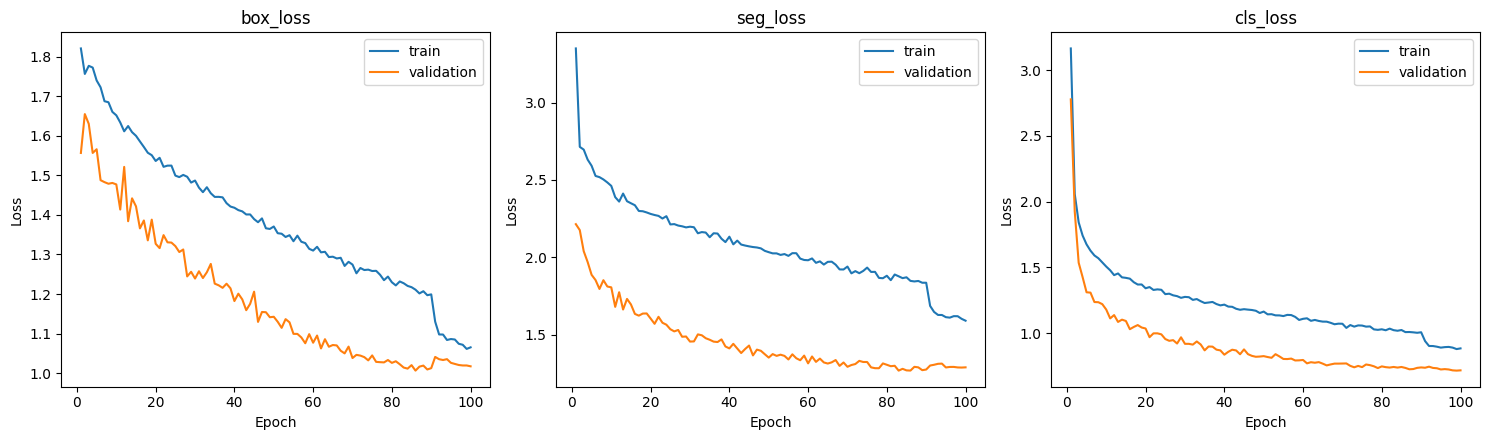

In [ ]:
plt.close('all')

componentes = [c for c in ["box_loss", "seg_loss", "cls_loss", "dfl_loss"] if f"train/{c}" in df.columns]

fig, axes = plt.subplots(1, len(componentes), figsize=(5*len(componentes), 4.5))
if len(componentes) == 1:
    axes = [axes]

for ax, comp in zip(axes, componentes):
    ax.plot(df["epoch"], df[f"train/{comp}"], label="train")
    ax.plot(df["epoch"], df[f"val/{comp}"], label="validation")
    ax.set_title(comp)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.savefig(f"{RUN_DIR}/loss_treino_validacao_seg.png", dpi=150)
plt.show()

## Curvas de mAP por epoca (box e mascara)

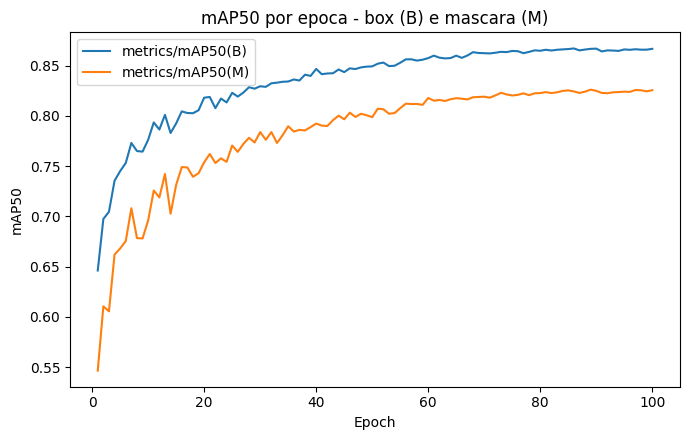

In [ ]:
plt.close('all')

map_cols = [c for c in df.columns if c.startswith("metrics/mAP50(")]
plt.figure(figsize=(7, 4.5))
for col in map_cols:
    plt.plot(df["epoch"], df[col], label=col)
plt.xlabel("Epoch")
plt.ylabel("mAP50")
plt.title("mAP50 por epoca - box (B) e mascara (M)")
plt.legend()
plt.tight_layout()
plt.savefig(f"{RUN_DIR}/map_por_epoca_seg.png", dpi=150)
plt.show()

## Avaliacao final no split de teste

In [ ]:
metrics_test = model.val(data=str(DATA_YAML_PATH), split="test")
print(metrics_test.results_dict)

Ultralytics 8.4.172 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 136 layers, 2,689,274 parameters, 0 gradients, 9.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 144.1±65.0 MB/s, size: 620.8 KB)
val: Scanning /content/dataset/labels/test... 610 images, 63 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 673/673 365.9it/s 1.8s
val: /content/dataset/images/test/20260704145559-f04dfb70_jpg.rf.bR6AWJDMfUTBaFujNSJ0.jpg: corrupt JPEG restored and saved
val: New cache created: /content/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 43/43 1.9it/s 22.8s
                   all        673       3795       0.87      0.717      0.811      0.596       0.84      0.682      0.754      0.429
                  corn        610       3795       0.87      0.717      0.811      0.596       0.84      0.682      0.754      0.429


## Backup final (com os graficos novos)

Roda de novo o backup depois de gerar os graficos, pra eles irem juntos pro Drive.

In [ ]:
destino_zip = shutil_lib.make_archive(f"/content/drive/MyDrive/milho/{BACKUP_NAME}", 'zip', RUN_DIR)
print("Backup final salvo em:", destino_zip)

from google.colab import files
files.download(destino_zip)

Backup final salvo em: /content/drive/MyDrive/milho/relatorio_treino_segmentacao_completo.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>